# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.


**Dataset yang digunakan: Bank Marketing** ([UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing), DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306), lisensi CC BY 4.0).

Dataset ini berasal dari kampanye pemasaran lewat telepon sebuah bank di Portugal (Mei 2008 – November 2010). Setiap baris adalah satu nasabah yang dihubungi, dengan target `y`: apakah nasabah tersebut **berlangganan deposito berjangka** (`yes`/`no`).

- Berkas: `bank-full.csv` (45.211 baris, 16 fitur + 1 target, pemisah `;`).
- Fitur nasabah: `age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan`.
- Fitur kontak kampanye saat ini: `contact`, `day`, `month`, `duration`, `campaign`.
- Fitur kampanye sebelumnya: `pdays`, `previous`, `poutcome`.

**Tujuan:** menyiapkan data agar model dapat memperkirakan nasabah mana yang paling mungkin berlangganan **sebelum** ditelepon, sehingga tim pemasaran dapat memprioritaskan panggilan.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

Dataset dibaca dari folder `bank_marketing_raw/` di repository. Jika berkas belum ada (misalnya saat notebook dibuka langsung di Colab), berkas diunduh dari UCI terlebih dahulu.

In [2]:
RAW_DIR = Path("../bank_marketing_raw") if Path("../bank_marketing_raw/bank-full.csv").exists() else Path("bank_marketing_raw")
RAW_PATH = RAW_DIR / "bank-full.csv"

if not RAW_PATH.exists():
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    inner = zipfile.ZipFile(io.BytesIO(outer.read("bank.zip")))
    RAW_PATH.write_bytes(inner.read("bank-full.csv"))
    print("Dataset diunduh dari UCI ke", RAW_PATH)

df = pd.read_csv(RAW_PATH, sep=";")
print("Ukuran data:", df.shape)
df.head()

Dataset diunduh dari UCI ke bank_marketing_raw/bank-full.csv
Ukuran data: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


**Hasil:** data termuat lengkap, 45.211 baris dan 17 kolom. Sebanyak 7 kolom numerik (`int64`) dan 10 kolom teks (9 fitur kategorikal + target `y`). Semua kolom terisi (non-null), sehingga perlu dicek apakah ada nilai kosong yang "tersamar".

# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

### 4.1 Kualitas data: missing value, nilai `unknown`, dan duplikasi

In [4]:
print("Missing value per kolom:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "tidak ada")
print("\nJumlah baris duplikat:", df.duplicated().sum())

unknown = (df == "unknown").sum()
unknown = unknown[unknown > 0].to_frame("jumlah_unknown")
unknown["persen"] = (unknown["jumlah_unknown"] / len(df) * 100).round(2)
unknown

Missing value per kolom:
tidak ada

Jumlah baris duplikat: 0


,jumlah_unknown,persen
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


### 4.2 Distribusi target

y
no     39922
yes     5289
Name: count, dtype: int64

Proporsi:
 y
no     88.3
yes    11.7
Name: proportion, dtype: float64


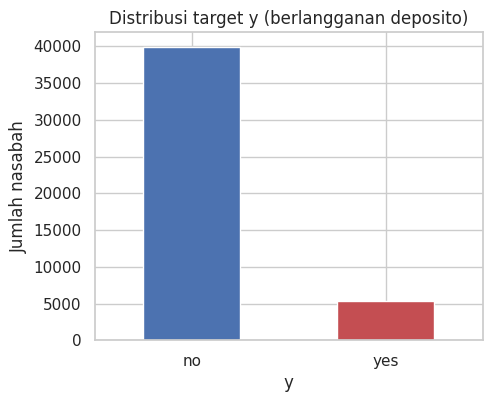

In [5]:
target_counts = df["y"].value_counts()
print(target_counts)
print("\nProporsi:\n", (df["y"].value_counts(normalize=True) * 100).round(2))

ax = target_counts.plot.bar(color=["#4C72B0", "#C44E52"], figsize=(5, 4), rot=0)
ax.set_title("Distribusi target y (berlangganan deposito)")
ax.set_xlabel("y")
ax.set_ylabel("Jumlah nasabah")
plt.show()

**Insight:** target sangat **tidak seimbang**: hanya **11,7%** nasabah (5.289) yang berlangganan, sedangkan 88,3% (39.922) tidak. Akibatnya:
- akurasi saja akan menyesatkan (model yang selalu menebak "no" sudah 88% akurat), sehingga nanti saya mengutamakan **F1, recall, dan ROC-AUC**;
- pembagian train/test harus **stratified** agar proporsi kelas tetap sama.

### 4.3 Statistik dan distribusi fitur numerik

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


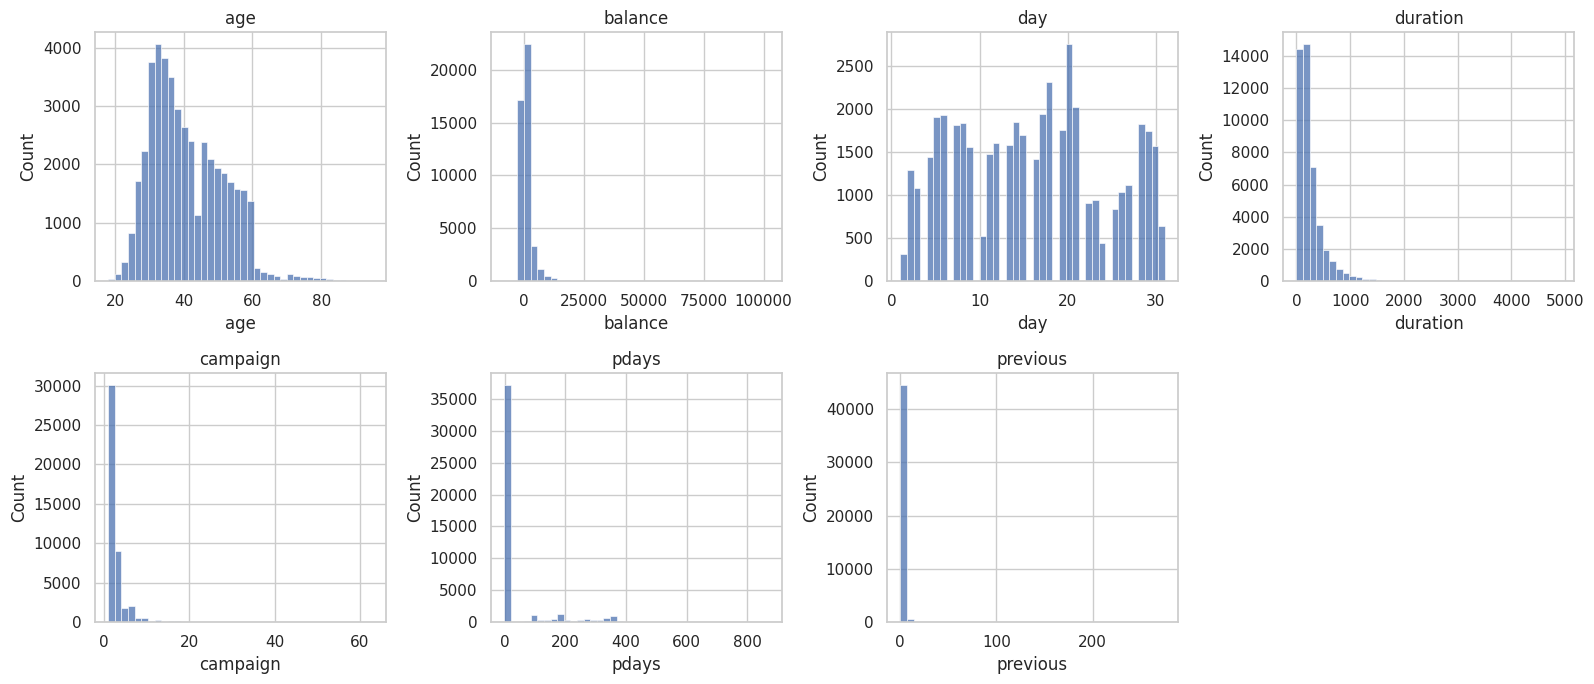

In [6]:
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
display(df[num_cols].describe().T)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color="#4C72B0")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

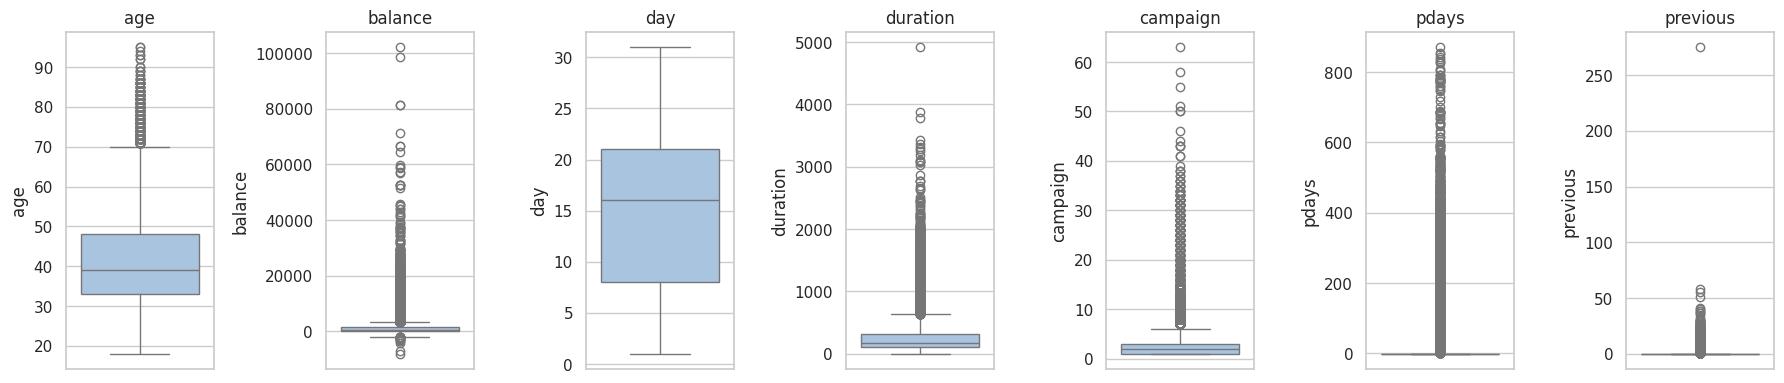

Jumlah outlier (aturan IQR) per kolom:


,0
age,487
balance,4729
day,0
duration,3235
campaign,3064
pdays,8257
previous,8257


In [7]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#A0C4E8")
    ax.set_title(col)
plt.tight_layout()
plt.show()

q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
print("Jumlah outlier (aturan IQR) per kolom:")
outliers

**Insight:**
- Tidak ada missing value maupun duplikat, tetapi ada nilai **`unknown`** yang berperan sebagai nilai kosong: `job` 0,64%, `education` 4,11%, `contact` 28,80%, dan `poutcome` 81,75%.
- `balance`, `duration`, `campaign`, dan `previous` sangat **miring ke kanan** dengan outlier ekstrem (misalnya `balance` hingga 102.127, `campaign` hingga 63 panggilan, `previous` hingga 275). Aturan IQR menandai 4.729 outlier pada `balance` dan 3.064 pada `campaign`.
- `pdays` bernilai **-1** pada lebih dari 75% data. Nilai ini berarti nasabah belum pernah dihubungi, bukan angka hari sungguhan, sehingga perlu diperlakukan khusus.

### 4.4 Hubungan fitur kategorikal dengan target

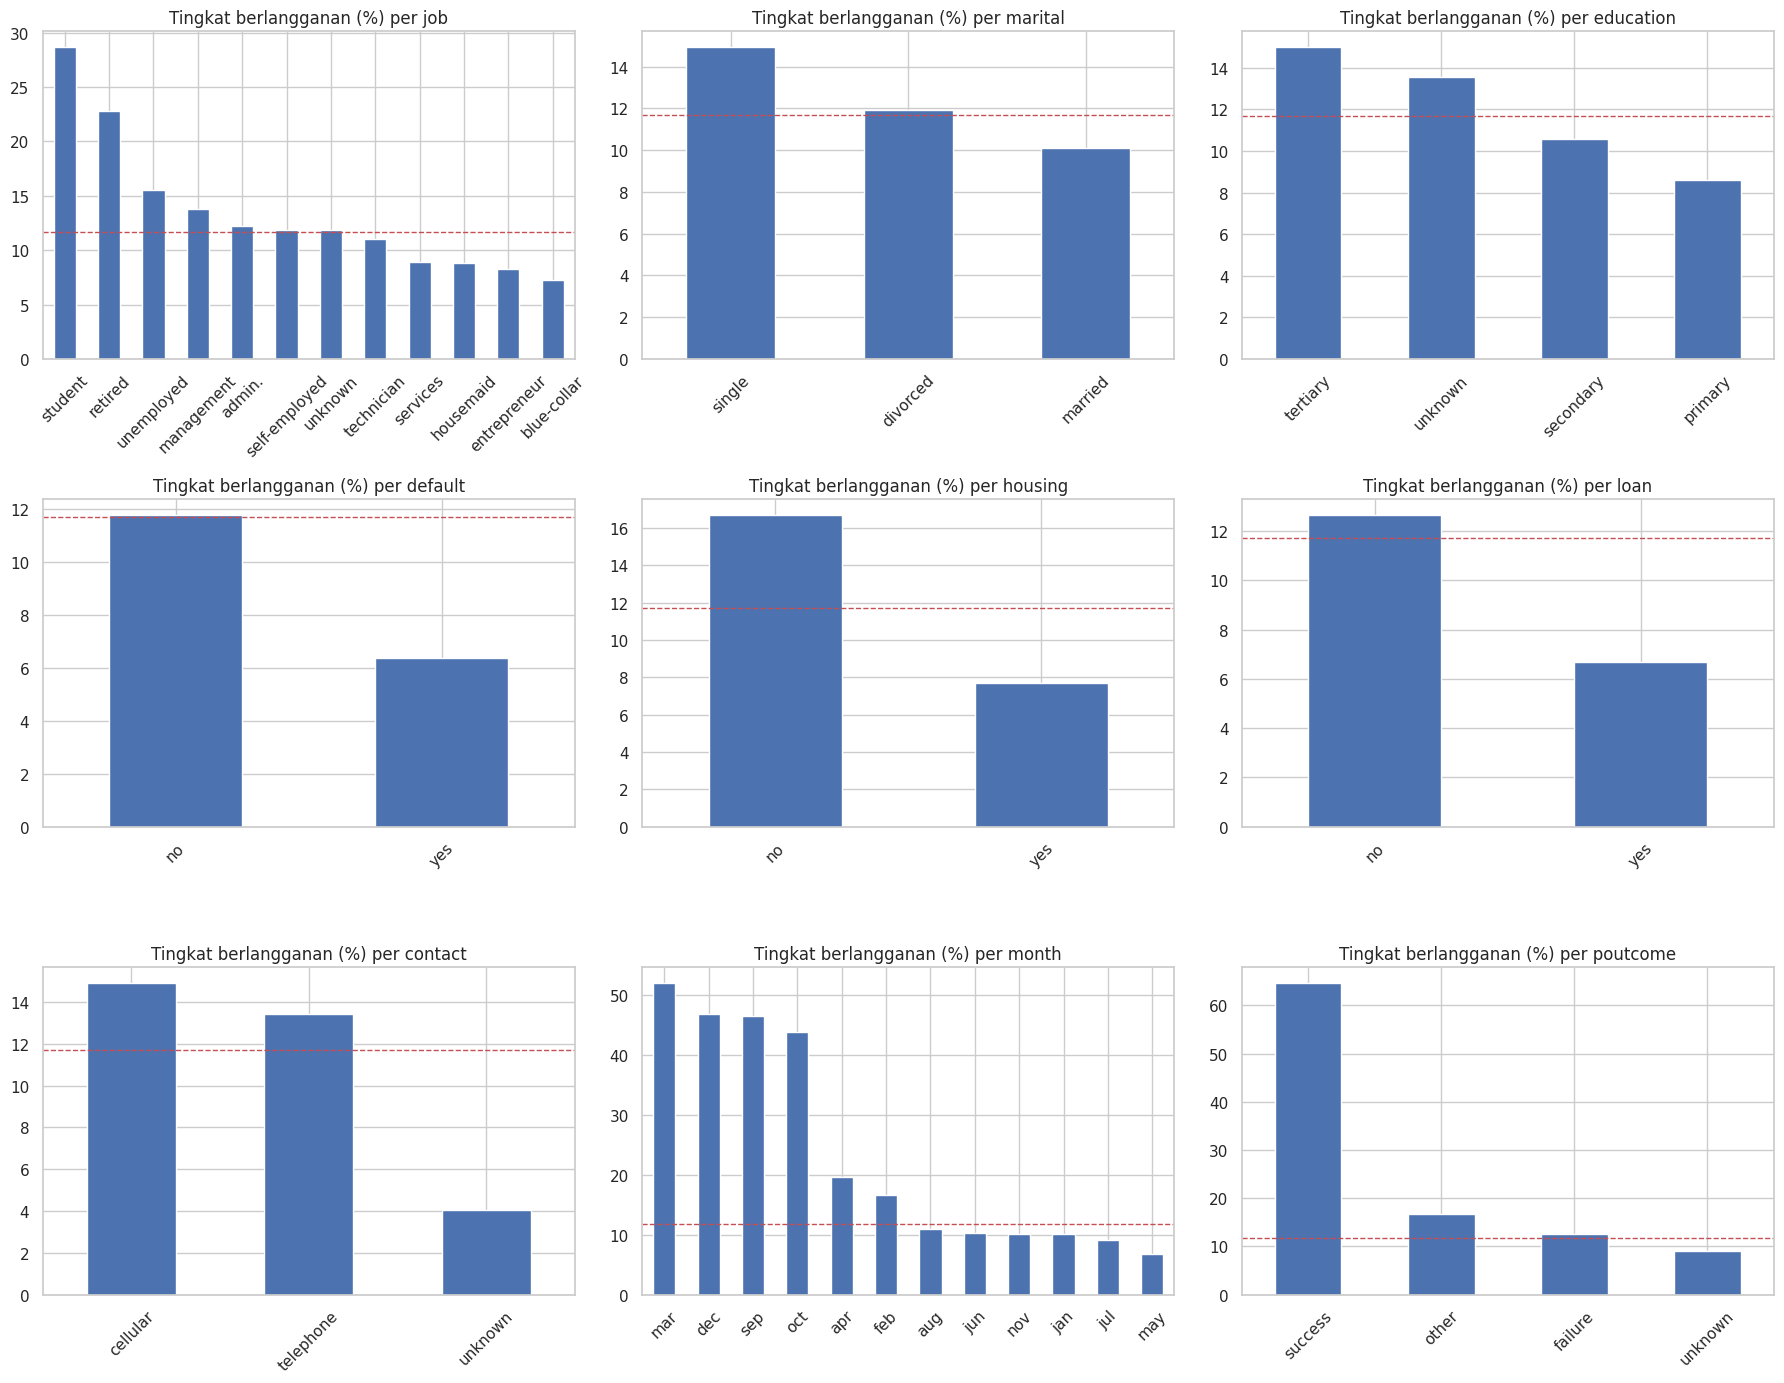

In [8]:
df["y_flag"] = (df["y"] == "yes").astype(int)
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)["y_flag"].mean().sort_values(ascending=False) * 100
    rate.plot.bar(ax=ax, color="#4C72B0")
    ax.axhline(df["y_flag"].mean() * 100, color="#C44E52", ls="--", lw=1)
    ax.set_title(f"Tingkat berlangganan (%) per {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [9]:
for col in ["poutcome", "contact", "month", "job"]:
    summary = df.groupby(col)["y_flag"].agg(jumlah="size", tingkat_berlangganan="mean")
    summary["tingkat_berlangganan"] = (summary["tingkat_berlangganan"] * 100).round(1)
    print(summary.sort_values("tingkat_berlangganan", ascending=False), "\n")

          jumlah  tingkat_berlangganan
poutcome                              
success     1511                  64.7
other       1840                  16.7
failure     4901                  12.6
unknown    36959                   9.2 

           jumlah  tingkat_berlangganan
contact                                
cellular    29285                  14.9
telephone    2906                  13.4
unknown     13020                   4.1 

       jumlah  tingkat_berlangganan
month                              
mar       477                  52.0
dec       214                  46.7
sep       579                  46.5
oct       738                  43.8
apr      2932                  19.7
feb      2649                  16.6
aug      6247                  11.0
jun      5341                  10.2
nov      3970                  10.2
jan      1403                  10.1
jul      6895                   9.1
may     13766                   6.7 

               jumlah  tingkat_berlangganan
job         

**Insight (garis merah putus-putus = rata-rata 11,7%):**
- **Hasil kampanye sebelumnya** paling berpengaruh: nasabah dengan `poutcome = success` berlangganan **64,7%**, jauh di atas yang `unknown` (9,2%).
- **Cara kontak**: `cellular` 14,9% dan `telephone` 13,4%, sedangkan `unknown` hanya 4,1%.
- **Bulan**: Maret (52,0%), Desember (46,7%), September (46,5%), dan Oktober (43,8%) sangat tinggi tetapi jumlah kontaknya sedikit. Mei adalah bulan dengan kontak terbanyak (13.766) tetapi tingkat berlangganannya terendah (6,7%).
- **Pekerjaan**: `student` (28,7%) dan `retired` (22,8%) paling tinggi; `blue-collar` dan `entrepreneur` paling rendah.
- Nasabah **tanpa** cicilan rumah (`housing = no`, 16,7% vs 7,7%) dan tanpa pinjaman pribadi (`loan = no`, 12,7% vs 6,7%) lebih sering berlangganan. Pendidikan `tertiary` (15,0%) juga di atas rata-rata.

### 4.5 Fitur numerik terhadap target dan korelasi

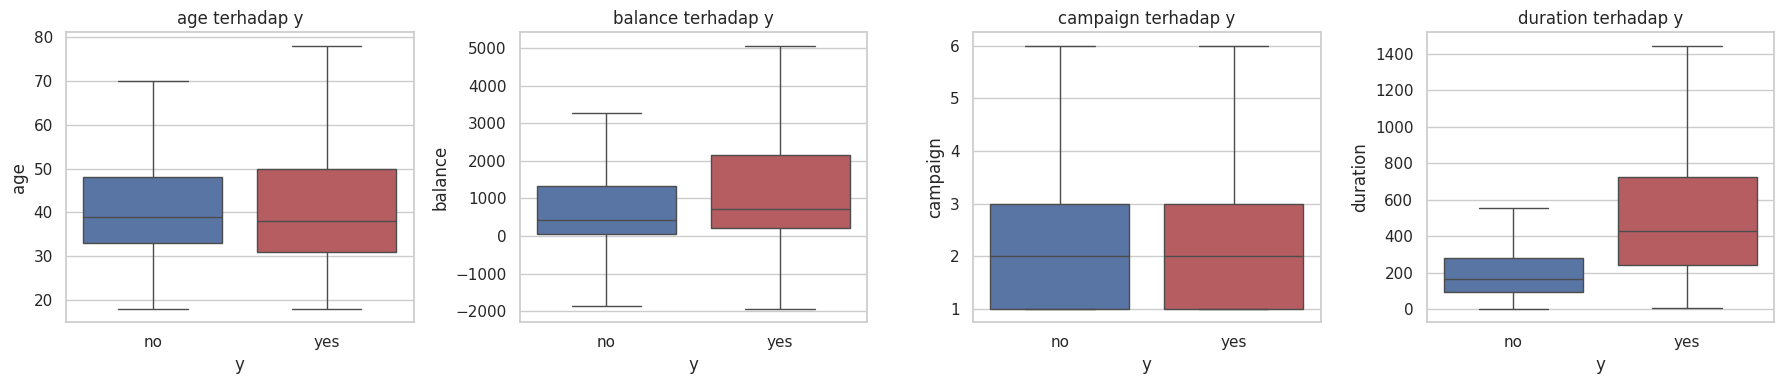

y,median_no,median_yes
age,39.0,38.0
balance,417.0,733.0
day,16.0,15.0
duration,164.0,426.0
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


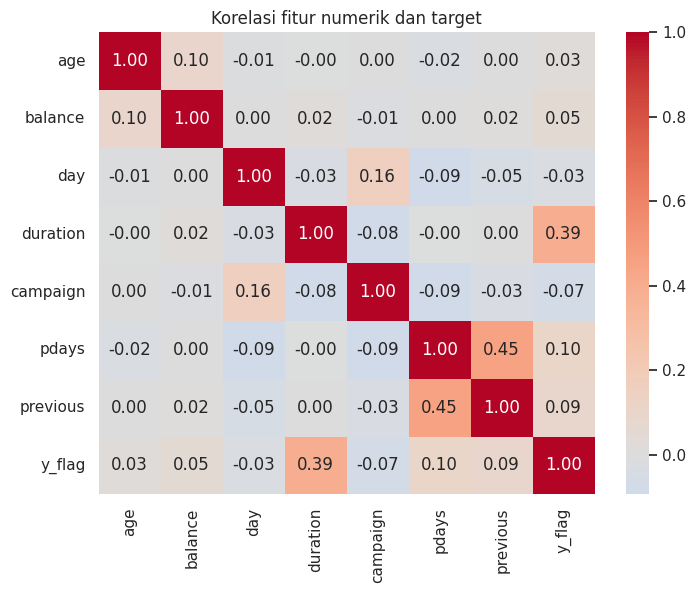

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["age", "balance", "campaign", "duration"]):
    sns.boxplot(data=df, x="y", y=col, ax=ax, hue="y", palette=["#4C72B0", "#C44E52"], legend=False, showfliers=False)
    ax.set_title(f"{col} terhadap y")
plt.tight_layout()
plt.show()

display(df.groupby("y")[num_cols].median().T.rename(columns={"no": "median_no", "yes": "median_yes"}))

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ["y_flag"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi fitur numerik dan target")
plt.show()

**Insight:**
- **`duration` adalah fitur dengan korelasi tertinggi terhadap target (0,395)**: median durasi telepon nasabah yang berlangganan 426 detik vs 164 detik. Namun durasi baru diketahui **setelah** telepon selesai, sehingga fitur ini membocorkan hasil (*data leakage*) dan tidak boleh dipakai untuk memilih nasabah yang akan ditelepon.
- Semakin sering dihubungi dalam satu kampanye, semakin kecil peluangnya: nasabah yang dihubungi 1 kali berlangganan 14,6%, sedangkan yang dihubungi lebih dari 3 kali hanya 7,4% (korelasi `campaign` -0,073).
- `balance` sedikit lebih tinggi pada nasabah yang berlangganan (median 733 vs 417). `age` hampir tidak berbeda pada median, tetapi pola per kelompok umur tidak linear: usia ≤25 tahun 24,0% dan >60 tahun 42,3%, sementara usia 36–60 tahun sekitar 9–10%. Karena itu saya menambahkan **binning umur**.
- Korelasi antarfitur numerik lain rendah, sehingga tidak ada multikolinearitas yang berarti; `pdays` dan `previous` saling berkaitan karena sama-sama menggambarkan riwayat kampanye sebelumnya.

### 4.6 Nasabah yang pernah dihubungi pada kampanye sebelumnya (`pdays`)

In [11]:
df["pernah_dihubungi"] = (df["pdays"] != -1).astype(int)
print(df.groupby("pernah_dihubungi")["y_flag"].agg(jumlah="size", tingkat_berlangganan="mean"))
df = df.drop(columns=["y_flag", "pernah_dihubungi"])

                  jumlah  tingkat_berlangganan
pernah_dihubungi                              
0                  36954              0.091573
1                   8257              0.230713


**Insight:** nasabah yang **pernah dihubungi** pada kampanye sebelumnya (8.257 orang) berlangganan **23,1%**, dua setengah kali lipat dibanding yang belum pernah (9,2%). Informasi ini lebih jelas sebagai fitur biner `previously_contacted` daripada angka `pdays = -1`.

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

Berdasarkan EDA, tahapan preprocessing yang saya lakukan:

1. **Duplikasi**: diperiksa dan dihapus bila ada.
2. **Membuang `duration`**: durasi panggilan baru diketahui setelah telepon selesai, dan sangat menentukan `y`. Memakainya berarti membocorkan target (*data leakage*), sehingga model tidak bisa dipakai untuk memilih nasabah **sebelum** ditelepon.
3. **Fitur dari `pdays`**: nilai `-1` berarti belum pernah dihubungi. Saya buat fitur biner `previously_contacted`, lalu nilai `-1` pada `pdays` diganti `0`.
4. **Nilai `unknown`**: pada `job` dan `education` (porsinya kecil) diisi dengan modus. Pada `contact` dan `poutcome` dipertahankan sebagai kategori tersendiri karena porsinya besar dan bermakna ("tidak tercatat" / "belum ada kampanye sebelumnya").
5. **Binning**: `age` dikelompokkan menjadi `age_group`.
6. **Encoding**: kolom biner `default`, `housing`, `loan` menjadi 0/1; target `y` menjadi 0/1; kolom kategorikal lain di-*one-hot encode*.
7. **Pembagian data**: train/test 80/20 secara **stratified** karena kelas tidak seimbang.
8. **Outlier**: nilai ekstrem pada `balance`, `campaign`, `pdays`, `previous` di-*capping* dengan aturan IQR (batas dihitung dari data latih).
9. **Standardisasi**: fitur numerik di-*scaling* dengan `StandardScaler` yang di-*fit* hanya pada data latih.

In [12]:
data = df.copy()

# 1. Duplikasi
print("Duplikat dihapus:", data.duplicated().sum())
data = data.drop_duplicates()

# 2. Buang fitur yang membocorkan target
data = data.drop(columns=["duration"])

# 3. Fitur dari pdays
data["previously_contacted"] = (data["pdays"] != -1).astype(int)
data["pdays"] = data["pdays"].where(data["pdays"] != -1, 0)

# 4. Nilai unknown pada job dan education diisi modus
for col in ["job", "education"]:
    mode = data.loc[data[col] != "unknown", col].mode()[0]
    data[col] = data[col].replace("unknown", mode)
    print(f"{col}: unknown diganti dengan '{mode}'")

# 5. Binning umur
data["age_group"] = pd.cut(data["age"], bins=[0, 25, 35, 45, 60, 120],
                           labels=["<=25", "26-35", "36-45", "46-60", ">60"]).astype(str)

# 6. Encoding biner dan target
for col in ["default", "housing", "loan"]:
    data[col] = (data[col] == "yes").astype(int)
data["y"] = (data["y"] == "yes").astype(int)
data.head()

Duplikat dihapus: 0
job: unknown diganti dengan 'blue-collar'
education: unknown diganti dengan 'secondary'


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y,previously_contacted,age_group
0,58,management,married,tertiary,0,2143,1,0,unknown,5,may,1,0,0,unknown,0,0,46-60
1,44,technician,single,secondary,0,29,1,0,unknown,5,may,1,0,0,unknown,0,0,36-45
2,33,entrepreneur,married,secondary,0,2,1,1,unknown,5,may,1,0,0,unknown,0,0,26-35
3,47,blue-collar,married,secondary,0,1506,1,0,unknown,5,may,1,0,0,unknown,0,0,46-60
4,33,blue-collar,single,secondary,0,1,0,0,unknown,5,may,1,0,0,unknown,0,0,26-35


In [13]:
# 7. Pembagian data stratified
X = data.drop(columns=["y"])
y = data["y"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi yes train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))

# 8. Capping outlier dengan batas IQR dari data latih
cap_cols = ["balance", "campaign", "pdays", "previous"]
bounds = {}
for col in cap_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    bounds[col] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr) if iqr > 0 else (X_train[col].min(), X_train[col].quantile(0.99))
    X_train[col] = X_train[col].clip(*bounds[col])
    X_test[col] = X_test[col].clip(*bounds[col])
pd.DataFrame(bounds, index=["batas_bawah", "batas_atas"]).T

Train: (36168, 17) | Test: (9043, 17)
Proporsi yes train/test: 0.117 0.117


,batas_bawah,batas_atas
balance,-1960.375,3464.625
campaign,-2.000,6.000
pdays,0.000,370.000
previous,0.000,9.000


In [14]:
# 9. One-hot encoding dan standardisasi
numeric_features = ["age", "balance", "day", "campaign", "pdays", "previous"]
binary_features = ["default", "housing", "loan", "previously_contacted"]
categorical_features = ["job", "marital", "education", "contact", "month", "poutcome", "age_group"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("bin", "passthrough", binary_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])
train_arr = preprocessor.fit_transform(X_train)
test_arr = preprocessor.transform(X_test)
feature_names = [name.split("__", 1)[1] for name in preprocessor.get_feature_names_out()]

train_processed = pd.DataFrame(train_arr, columns=feature_names, index=X_train.index)
test_processed = pd.DataFrame(test_arr, columns=feature_names, index=X_test.index)
train_processed["y"] = y_train.values
test_processed["y"] = y_test.values
print("Jumlah fitur setelah preprocessing:", len(feature_names))
train_processed.head()

Jumlah fitur setelah preprocessing: 51


,age,balance,day,campaign,pdays,previous,default,housing,loan,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,marital_single,education_primary,...,contact_cellular,contact_telephone,contact_unknown,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,age_group_26-35,age_group_36-45,age_group_46-60,age_group_<=25,age_group_>60,y
24001,-0.460434,-0.063364,1.582124,-0.245119,-0.418751,-0.357711,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0
43409,-1.589641,2.149420,-1.298384,1.004857,1.513173,4.420127,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
20669,0.292371,-0.587744,-0.458236,1.004857,-0.418751,-0.357711,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1
18810,0.668773,-0.795116,1.822166,2.254833,-0.418751,-0.357711,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
23130,-0.272233,-0.576695,1.222060,2.254833,-0.418751,-0.357711,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0


In [15]:
# Pemeriksaan hasil dan penyimpanan
assert train_processed.isna().sum().sum() == 0 and test_processed.isna().sum().sum() == 0
display(train_processed[numeric_features].describe().T[["mean", "std"]].round(3))

OUT_DIR = Path("bank_marketing_preprocessing")
OUT_DIR.mkdir(exist_ok=True)
train_processed.to_csv(OUT_DIR / "train.csv", index=False)
test_processed.to_csv(OUT_DIR / "test.csv", index=False)
print("Tersimpan:", sorted(p.name for p in OUT_DIR.iterdir()))

,mean,std
age,-0.0,1.0
balance,0.0,1.0
day,0.0,1.0
campaign,-0.0,1.0
pdays,-0.0,1.0
previous,-0.0,1.0


Tersimpan: ['test.csv', 'train.csv']


**Hasil preprocessing:**
- Tidak ada duplikat; `duration` dibuang; nilai `unknown` pada `job` diganti `blue-collar` dan pada `education` diganti `secondary` (modus).
- Data dibagi menjadi **36.168 baris latih** dan **9.043 baris uji** dengan proporsi kelas yang sama (11,7% `yes`).
- Batas capping IQR dari data latih: `balance` -1.960 sampai 3.465, `campaign` maksimal 6, `pdays` maksimal 370, `previous` maksimal 9. Untuk `pdays` dan `previous`, IQR bernilai 0 karena sebagian besar nilainya 0, sehingga batas atas memakai persentil ke-99.
- Setelah one-hot encoding dan standardisasi terdapat **51 fitur** numerik tanpa nilai kosong; fitur numerik memiliki rata-rata 0 dan simpangan baku 1.
- Hasil disimpan di `bank_marketing_preprocessing/train.csv` dan `test.csv`, siap dipakai untuk melatih model. Langkah yang sama dijadikan otomatis di `automate_ruthami.py`.